# 12 · Snow and river: snowmelt timing, a degree-day melt model, and river volatility

**Person 2 (Leora).** The water side of the trophic-cascade debate: has snowmelt shifted, how much does snow control the river, and how volatile is the river?

| Section | Question | Methods |
|---|---|---|
| 1 | What does a century of river flow look like? | EDA, daily climatology, STL decomposition |
| 2 | Have snowmelt and the river's spring peak shifted earlier? (Q5) | Centre-of-timing dates, Mann–Kendall, Sen's slope |
| 3 | Is the snowpack itself changing, and does it set the river's timing? (Q4, Q5) | Trend tests on the winter severity index; regression of river timing on snow |
| 4 | Can a simple physical model reproduce snowmelt? (Q4) | Degree-day snowmelt ODE, calibrated and tested year by year |
| 5 | Can monthly flow be forecast? | ADF/KPSS, SARIMA identification, rolling-origin evaluation |
| 6 | How volatile is the river, and how extreme was the 2022 flood? (Q7) | Ornstein–Uhlenbeck vs GARCH vs EGARCH, GEV return periods |
| 7 | Summary | |

**Outputs used elsewhere:** `data/processed/river_annual_features.csv` (summer low flow and timing per water year) feeds notebook 11's "does water limit willows?" question (Q6).

**Water year** = 1 October to 30 September, labelled by the year it ends (water year 2022 = Oct 2021 – Sep 2022). This matches the winter severity index and the elk counts.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymannkendall as mk
from arch import arch_model
from scipy import stats
import statsmodels.api as sm
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW, PROC = ROOT / "data" / "raw", ROOT / "data" / "processed"
FIG, TAB = ROOT / "reports" / "figures", ROOT / "reports" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"P2_{name}.png", dpi=200)

def trend(series, label):
    """Mann–Kendall (original and Hamed–Rao autocorrelation-corrected) + Sen's slope per decade."""
    s = series.dropna()
    o, h = mk.original_test(s.values), mk.hamed_rao_modification_test(s.values)
    return {"series": label, "years": f"{s.index.min()}–{s.index.max()}", "n": len(s),
            "Sen slope per decade": round(10 * o.slope, 3),
            "MK p": round(o.p, 4), "MK p (autocorr-corrected)": round(h.p, 4), "direction": o.trend}

## 0. Data

Daily mean discharge (cubic feet per second) for **USGS 06191500, Yellowstone River at Corwin Springs, MT**, the gauge just north of the park on the northern range. The record starts in August 1889, but **1895–1910 is missing**, so the analysis uses the unbroken run of complete water years **1911–2026** (116 years). Codes: `A` approved, `A:e` approved but estimated, `P` provisional (recent months).

In [2]:
raw = pd.read_csv(RAW / "usgs_06191500_daily_flow.txt", sep="\t", comment="#", dtype=str)
raw = raw[raw["agency_cd"] == "USGS"]                      # drops the column-format row
qcol = [c for c in raw.columns if c.endswith("_00003")][0]
flow = pd.DataFrame({"Q": pd.to_numeric(raw[qcol], errors="coerce").values,
                     "code": raw[qcol + "_cd"].values},
                    index=pd.to_datetime(raw["datetime"])).asfreq("D")
flow["wy"] = flow.index.year + (flow.index.month >= 10)
flow["dowy"] = (flow.index - pd.to_datetime((flow["wy"] - 1).astype(str) + "-10-01").values).days + 1

n_days = flow.groupby("wy")["Q"].count()
expected = flow.groupby("wy").size()
complete = n_days[(n_days == expected) & (expected >= 365)].index
WY = [w for w in complete if 1911 <= w <= 2026]
print(f"Complete water years used: {WY[0]}–{WY[-1]} ({len(WY)}); missing values inside them: "
      f"{flow[flow.wy.isin(WY)].Q.isna().sum()}")
print(flow.loc[flow.wy.isin(WY), "code"].value_counts().to_string())

sev = pd.read_csv(PROC / "winter_severity_index.csv", index_col="Year")
temp = pd.read_csv(PROC / "monthly_temperature.csv", index_col="Month", parse_dates=True)
f = flow[flow.wy.isin(WY)].copy()
f["logQ"] = np.log(f["Q"])
f[["Q"]].describe().T

Complete water years used: 1911–2026 (116); missing values inside them: 0
code
A      41406
A:e      794
P        169


,count,mean,std,min,25%,50%,75%,max
Q,42369.0,3111.411622,3822.122501,380.0,958.0,1390.0,3420.0,47200.0


## 1. What a century of river flow looks like

The river is a snowmelt river: low and steady from August to March, then a single large pulse in May–June when the mountain snowpack melts. The June 2022 flood is drawn on top of the normal range.

Record peak: 47,200 cfs on 2022-06-13; median June flow: 10,700 cfs


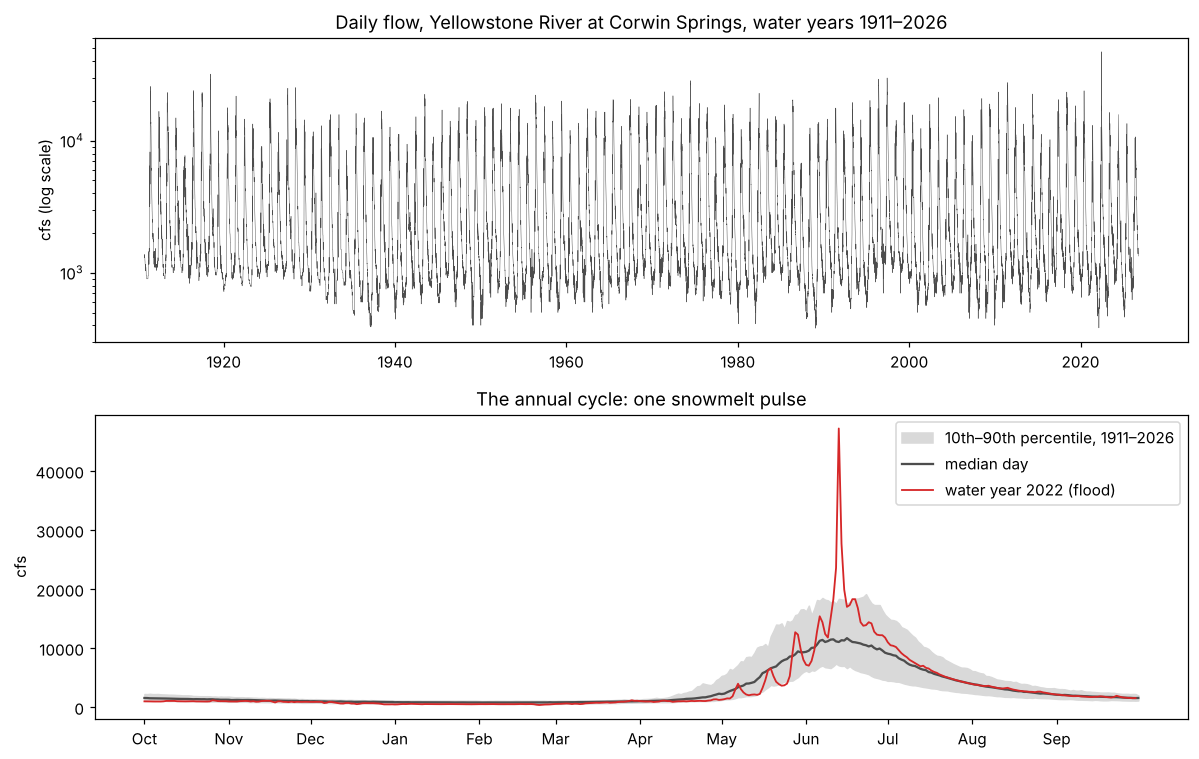

In [3]:
clim = f.groupby("dowy")["Q"].quantile([0.1, 0.5, 0.9]).unstack()
fig, ax = plt.subplots(2, 1, figsize=(11, 7))
ax[0].plot(f.index, f["Q"], lw=0.3, color="0.3")
ax[0].set_yscale("log"); ax[0].set_ylabel("cfs (log scale)")
ax[0].set_title("Daily flow, Yellowstone River at Corwin Springs, water years 1911–2026")
ax[1].fill_between(clim.index, clim[0.1], clim[0.9], color="0.85", label="10th–90th percentile, 1911–2026")
ax[1].plot(clim.index, clim[0.5], color="0.3", label="median day")
f22 = f[f.wy == 2022]
ax[1].plot(f22["dowy"], f22["Q"], color="C3", lw=1.2, label="water year 2022 (flood)")
ticks = [1, 32, 62, 93, 124, 152, 183, 213, 244, 274, 305, 336]
ax[1].set_xticks(ticks, ["Oct", "Nov", "Dec", "Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep"])
ax[1].set_ylabel("cfs"); ax[1].legend(); ax[1].set_title("The annual cycle: one snowmelt pulse")
save(fig, "01_flow_overview")
pk = f["Q"].idxmax()
print(f"Record peak: {f.loc[pk, 'Q']:,.0f} cfs on {pk.date()}; median June flow: {f[f.index.month == 6].Q.median():,.0f} cfs")

Seasonal swing (log units, max−min within year): 2.51 in the 1910s vs 2.52 in the last decade


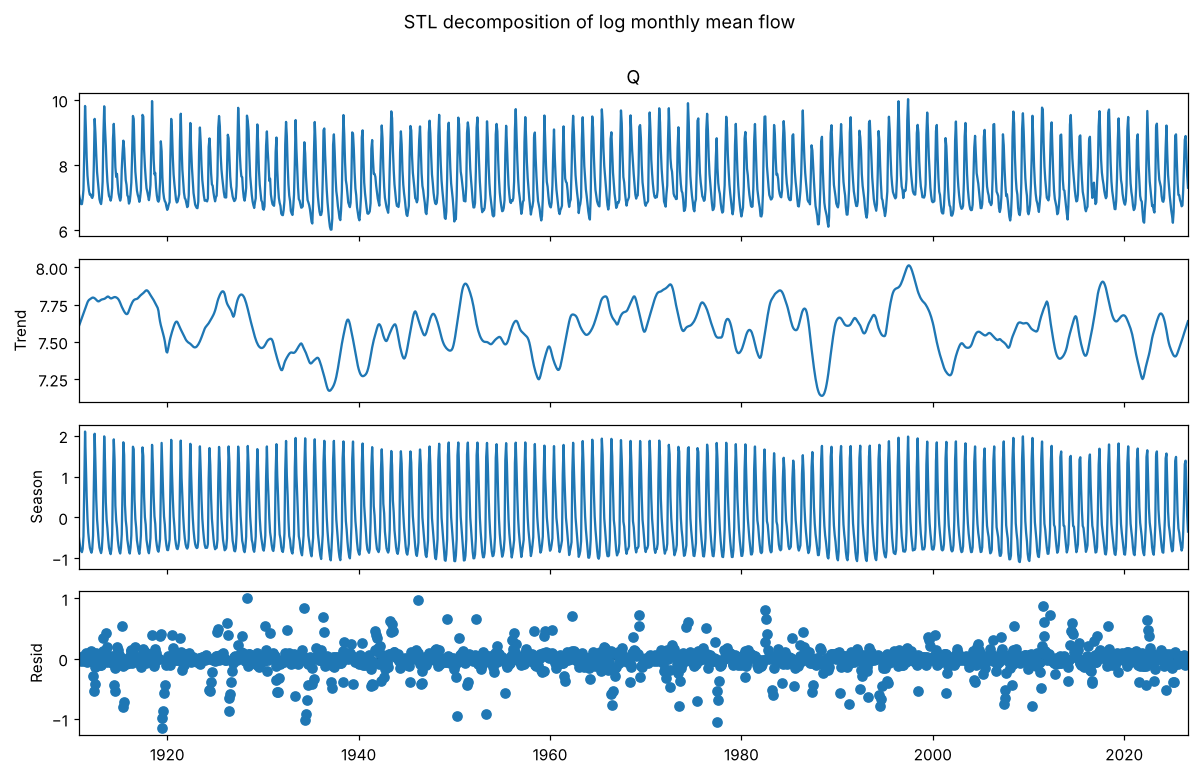

In [4]:
monthly = f["Q"].resample("MS").mean()
logm = np.log(monthly)
stl = STL(logm, period=12, robust=True).fit()
fig = stl.plot(); fig.set_size_inches(11, 7)
fig.suptitle("STL decomposition of log monthly mean flow", y=1.0)
save(fig, "02_stl_monthly")
amp = stl.seasonal.groupby(stl.seasonal.index.year).agg(lambda s: s.max() - s.min())
print(f"Seasonal swing (log units, max−min within year): {amp.iloc[:10].mean():.2f} in the 1910s vs {amp.iloc[-10:].mean():.2f} in the last decade")

## 2. Have snowmelt and the spring peak shifted earlier? (Q5)

Four numbers per water year:

- **Centre of timing (CT):** the day by which half of the year's water has passed the gauge. The standard measure of snowmelt timing (Stewart, Cayan & Dettinger 2005).
- **Peak date:** day of the largest daily flow.
- **Mean flow:** total water in the year.
- **Summer low flow:** lowest 7-day average in July–September, the water left in late summer. This is the input to Q6.

Days are counted from 1 October (day 1). Day 245 ≈ 1 June.

Trends: Mann–Kendall test (does the series tend to go up or down?) and Sen's slope (median change per decade). The autocorrelation-corrected p-value (Hamed–Rao) guards against wet or dry runs of years faking a trend. Two windows: the full record, and 1950 onwards to compare with the Greater Yellowstone Climate Assessment (about 8 days earlier runoff since 1950).

In [5]:
def year_features(g):
    q = g["Q"].values
    cum = np.cumsum(q) / q.sum()
    summer = g[g.index.month.isin([7, 8, 9])]["Q"].rolling(7).mean()
    return pd.Series({
        "mean_Q": q.mean(),
        "peak_Q": q.max(),
        "peak_dowy": int(g["dowy"].values[q.argmax()]),
        "CT_dowy": int(g["dowy"].values[np.searchsorted(cum, 0.5)]),
        "low7_summer_Q": summer.min(),
        "aug_mean_Q": g[g.index.month == 8]["Q"].mean(),
        "spring_share": g[g.index.month.isin([4, 5])]["Q"].sum() / q.sum(),
    })

ann = f.groupby("wy").apply(year_features)
ann.index.name = "Year"
ann.to_csv(PROC / "river_annual_features.csv")
ann.describe().round(1)

,mean_Q,peak_Q,peak_dowy,CT_dowy,low7_summer_Q,aug_mean_Q,spring_share
count,116.0,116.0,116.0,116.0,116.0,116.0,116.0
mean,3111.4,17298.7,250.7,253.4,1646.5,3063.9,0.2
std,684.5,5679.6,12.1,9.1,415.2,997.1,0.1
min,1903.2,6790.0,219.0,229.0,854.4,1319.4,0.1
25%,2621.3,13475.0,242.8,247.0,1367.5,2308.4,0.2
50%,3050.9,16750.0,250.0,253.5,1597.9,2905.8,0.2
75%,3585.6,20250.0,258.2,260.0,1951.8,3793.8,0.3
max,5157.6,47200.0,279.0,272.0,2894.3,5810.0,0.4


In [6]:
rows = []
for lo in (1911, 1950):
    a = ann.loc[lo:]
    rows += [trend(a["CT_dowy"], f"centre of timing (days), from {lo}"),
             trend(a["peak_dowy"], f"peak date (days), from {lo}"),
             trend(np.log(a["mean_Q"]), f"log mean flow, from {lo}"),
             trend(np.log(a["low7_summer_Q"]), f"log summer 7-day low flow, from {lo}"),
             trend(a["spring_share"], f"share of flow in Apr–May, from {lo}")]
timing_trends = pd.DataFrame(rows).set_index("series")
timing_trends.to_csv(TAB / "P2_timing_trends.csv")
timing_trends

,years,n,Sen slope per decade,MK p,MK p (autocorr-corrected),direction
series,,,,,,
"centre of timing (days), from 1911",1911–2026,116,-0.812,0.0020,0.0020,decreasing
"peak date (days), from 1911",1911–2026,116,-0.788,0.0189,0.0267,decreasing
"log mean flow, from 1911",1911–2026,116,0.001,0.8805,0.8805,no trend
"log summer 7-day low flow, from 1911",1911–2026,116,-0.013,0.1017,0.1636,no trend
"share of flow in Apr–May, from 1911",1911–2026,116,0.008,0.0001,0.0004,increasing
"centre of timing (days), from 1950",1950–2026,77,-1.771,0.0001,0.0001,decreasing
"peak date (days), from 1950",1950–2026,77,-1.935,0.0015,0.0015,decreasing
"log mean flow, from 1950",1950–2026,77,-0.013,0.3013,0.3013,no trend
"log summer 7-day low flow, from 1950",1950–2026,77,-0.032,0.0255,0.0255,decreasing


Since 1950 the centre of timing moved -1.8 days per decade (≈ -13 days over 1950–2026); p = 0.0001 (autocorrelation-corrected 0.0001)


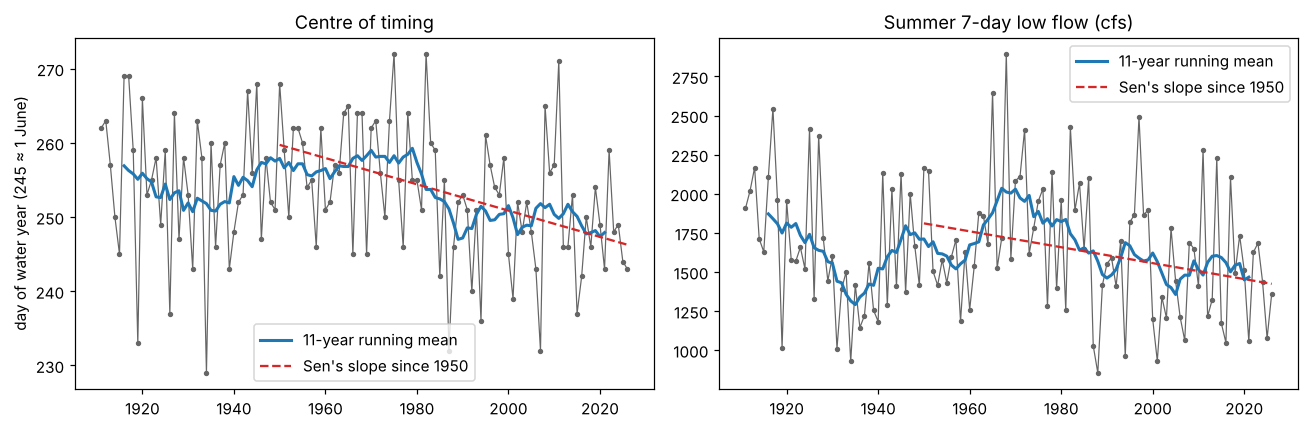

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a_, col, lab in [(ax[0], "CT_dowy", "Centre of timing"), (ax[1], "low7_summer_Q", "Summer 7-day low flow (cfs)")]:
    a_.plot(ann.index, ann[col], "o-", ms=2.5, lw=0.8, color="0.4")
    a_.plot(ann.index, ann[col].rolling(11, center=True).mean(), color="C0", lw=2, label="11-year running mean")
    s50 = ann.loc[1950:, col]
    sen = mk.original_test(s50.values)
    a_.plot(s50.index, sen.intercept + sen.slope * np.arange(len(s50)), "C3--", label="Sen's slope since 1950")
    a_.set_title(lab); a_.legend()
ax[0].set_ylabel("day of water year (245 ≈ 1 June)")
save(fig, "03_timing_lowflow")
ct = timing_trends.loc["centre of timing (days), from 1950"]
print(f"Since 1950 the centre of timing moved {ct['Sen slope per decade']:+.1f} days per decade "
      f"(≈ {ct['Sen slope per decade'] * (2026 - 1950) / 10:+.0f} days over 1950–2026); "
      f"p = {ct['MK p']} (autocorrelation-corrected {ct['MK p (autocorr-corrected)']})")

## 3. Is the snowpack changing, and does it set the river's timing? (Q4, Q5)

Uses `winter_severity_index.csv` (three SNOTEL stations: Northeast Entrance, Canyon, Parker Peak). `Severity_index` combines peak snow water equivalent (SWE), accumulated SWE and snow-covered days; `Melt_out_anom_days` is how many days later (+) or earlier (−) than usual the snow disappeared, averaged over stations. All three stations are present from 1982, so trends use 1982–2026.

In [8]:
s = sev.loc[1982:2026]
peak_cols = [c for c in s.columns if c.startswith("Peak_SWE_in__")]
s_peak = s[peak_cols].apply(lambda c: (c - c.mean()) / c.std()).mean(axis=1).rename("peak SWE (z, 3 stations)")
snow_trends = pd.DataFrame([
    trend(s["Severity_index"], "winter severity index"),
    trend(s_peak, "peak SWE, standardised"),
    trend(s["Melt_out_anom_days"], "melt-out date anomaly (days)"),
    trend(sev.loc[1967:2026, "Peak_SWE_in__northeast_entrance"], "peak SWE, Northeast Entrance only (in)"),
]).set_index("series")
snow_trends.to_csv(TAB / "P2_snow_trends.csv")
snow_trends

,years,n,Sen slope per decade,MK p,MK p (autocorr-corrected),direction
series,,,,,,
winter severity index,1982–2026,45,-0.101,0.3630,0.3630,no trend
"peak SWE, standardised",1982–2026,45,-0.019,0.8220,0.8220,no trend
melt-out date anomaly (days),1982–2026,45,-2.588,0.0734,0.0734,no trend
"peak SWE, Northeast Entrance only (in)",1967–2026,60,-0.905,0.0006,0.0046,decreasing


In [9]:
d = pd.concat([ann[["CT_dowy", "peak_dowy", "mean_Q", "low7_summer_Q"]],
               s[["Melt_out_anom_days"]], s_peak], axis=1).loc[1982:2026].dropna()
d["log_mean_Q"] = np.log(d["mean_Q"]); d["log_low7"] = np.log(d["low7_summer_Q"])
links = []
for y, X in [("CT_dowy", ["Melt_out_anom_days"]), ("CT_dowy", ["Melt_out_anom_days", "peak SWE (z, 3 stations)"]),
             ("log_mean_Q", ["peak SWE (z, 3 stations)"]), ("log_low7", ["peak SWE (z, 3 stations)", "Melt_out_anom_days"])]:
    r = sm.OLS(d[y], sm.add_constant(d[X])).fit(cov_type="HAC", cov_kwds={"maxlags": 2})
    for x in X:
        links.append({"model": f"{y} ~ " + " + ".join(X), "outcome": y, "predictor": x, "coef": round(r.params[x], 3),
                      "CI low": round(r.conf_int().loc[x, 0], 3), "CI high": round(r.conf_int().loc[x, 1], 3),
                      "p": round(r.pvalues[x], 4), "R2": round(r.rsquared, 2), "n": int(r.nobs)})
snow_river = pd.DataFrame(links)
snow_river.to_csv(TAB / "P2_snow_to_river.csv", index=False)
snow_river

,model,outcome,predictor,coef,CI low,CI high,p,R2,n
0,CT_dowy ~ Melt_out_anom_days,CT_dowy,Melt_out_anom_days,0.673,0.537,0.808,0.0000,0.78,45
1,"CT_dowy ~ Melt_out_anom_days + peak SWE (z, 3 ...",CT_dowy,Melt_out_anom_days,0.697,0.546,0.848,0.0000,0.78,45
2,"CT_dowy ~ Melt_out_anom_days + peak SWE (z, 3 ...",CT_dowy,"peak SWE (z, 3 stations)",-0.464,-1.891,0.962,0.5235,0.78,45
3,"log_mean_Q ~ peak SWE (z, 3 stations)",log_mean_Q,"peak SWE (z, 3 stations)",0.207,0.176,0.239,0.0000,0.68,45
4,"log_low7 ~ peak SWE (z, 3 stations) + Melt_out...",log_low7,"peak SWE (z, 3 stations)",0.084,0.031,0.137,0.0019,0.56,45
5,"log_low7 ~ peak SWE (z, 3 stations) + Melt_out...",log_low7,Melt_out_anom_days,0.012,0.008,0.016,0.0000,0.56,45


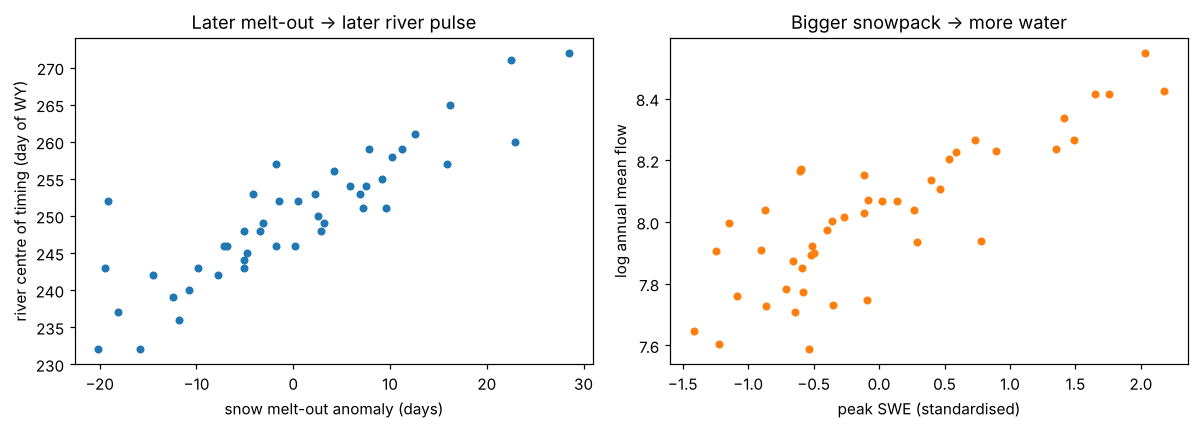

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(d["Melt_out_anom_days"], d["CT_dowy"], s=18)
ax[0].set_xlabel("snow melt-out anomaly (days)"); ax[0].set_ylabel("river centre of timing (day of WY)")
ax[0].set_title("Later melt-out → later river pulse")
ax[1].scatter(d["peak SWE (z, 3 stations)"], d["log_mean_Q"], s=18, color="C1")
ax[1].set_xlabel("peak SWE (standardised)"); ax[1].set_ylabel("log annual mean flow")
ax[1].set_title("Bigger snowpack → more water")
save(fig, "04_snow_to_river")

## 4. A degree-day snowmelt model (Q4, mathematical modelling)

The simplest physical snowmelt model says snow melts in proportion to how far the air is above freezing:

$$\frac{d\,\mathrm{SWE}}{dt} = \text{snowfall} - k\,\max(T - T_0,\ 0), \qquad T_0 = 32^\circ\mathrm{F}$$

After the snowpack peaks, snowfall is small, so the melt season is approximately $d\,\mathrm{SWE}/dt = -k\,(T-T_0)^+$. The **melt factor** $k$ (inches of water per °F-day) is the one parameter.

1. **Calibrate:** for each year at Northeast Entrance, $k$ = total melt from peak to melt-out ÷ total degree-days in that period.
2. **Test:** for each year, start at that year's peak SWE and step the ODE forward one day at a time (Euler) with that year's temperatures and $k$ = the median of the *other* years (leave-one-out, so the test is honest). Compare the predicted melt-out date with the observed one.
3. **Trend:** has $k$ changed?

Caveat: SNOTEL temperature sensors were replaced in the 2000s and the new ones read warmer; trends in temperature-based quantities need that caveat.

In [11]:
def load_snotel(path):
    d = pd.read_csv(path, comment="#", parse_dates=["Date"]).set_index("Date")
    d.columns = ["SWE", "DEPTH", "TAVG"][: d.shape[1]]
    d.loc[d["TAVG"] < -60, "TAVG"] = np.nan
    d["wy"] = d.index.year + (d.index.month >= 10)
    return d

ne = load_snotel(RAW / "snotel_northeast_entrance.csv")
melt_rows = []
for wy, g in ne.groupby("wy"):
    g = g.dropna(subset=["SWE"])
    if g.empty or g["SWE"].max() < 2:
        continue
    pk = g["SWE"].idxmax()
    after = g.loc[pk:]
    gone = after[after["SWE"] <= 0]
    if gone.empty:
        continue
    mo = gone.index[0]
    seg = g.loc[pk:mo]
    if seg["TAVG"].notna().mean() < 0.95 or len(seg) < 10:
        continue
    dd = (seg["TAVG"] - 32).clip(lower=0).fillna(0)
    melt_rows.append({"wy": wy, "peak_date": pk, "peak_SWE": g.loc[pk, "SWE"], "meltout_date": mo,
                      "degree_days": dd.iloc[:-1].sum(), "k": g.loc[pk, "SWE"] / dd.iloc[:-1].sum()})
melt = pd.DataFrame(melt_rows).set_index("wy")

def simulate(wy, k):
    g = ne[ne.wy == wy]
    swe = melt.loc[wy, "peak_SWE"]
    for day, t in g.loc[melt.loc[wy, "peak_date"]:, "TAVG"].fillna(32).items():
        swe -= k * max(t - 32, 0)
        if swe <= 0:
            return day
    return pd.NaT

melt["pred_meltout"] = [simulate(w, melt.drop(index=w)["k"].median()) for w in melt.index]
melt["error_days"] = (melt["pred_meltout"] - melt["meltout_date"]).dt.days
melt["k_mm_per_C_day"] = melt["k"] * 25.4 * 1.8
melt.to_csv(TAB / "P2_degree_day_model.csv")
obs_doy, pred_doy = melt["meltout_date"].dt.dayofyear, melt["pred_meltout"].dt.dayofyear
print(f"Years modelled: {melt.index.min()}–{melt.index.max()} (n = {len(melt)})")
print(f"Melt factor k: median {melt['k_mm_per_C_day'].median():.1f} mm per °C-day "
      f"(literature range for seasonal snow is roughly 2–7)")
print(f"Leave-one-out melt-out prediction: mean absolute error {melt['error_days'].abs().mean():.1f} days, "
      f"bias {melt['error_days'].mean():+.1f} days, correlation with observed r = {np.corrcoef(obs_doy, pred_doy)[0, 1]:.2f}")
print(f"Naive benchmark (always predict the average melt-out day): MAE {(obs_doy - obs_doy.mean()).abs().mean():.1f} days")
pd.DataFrame([trend(melt["k_mm_per_C_day"], "melt factor k (mm/°C/day)")]).set_index("series")

Years modelled: 1985–2026 (n = 41)
Melt factor k: median 3.1 mm per °C-day (literature range for seasonal snow is roughly 2–7)
Leave-one-out melt-out prediction: mean absolute error 4.1 days, bias -0.8 days, correlation with observed r = 0.93
Naive benchmark (always predict the average melt-out day): MAE 9.6 days


,years,n,Sen slope per decade,MK p,MK p (autocorr-corrected),direction
series,,,,,,
melt factor k (mm/°C/day),1985–2026,41,-0.161,0.1671,0.1671,no trend


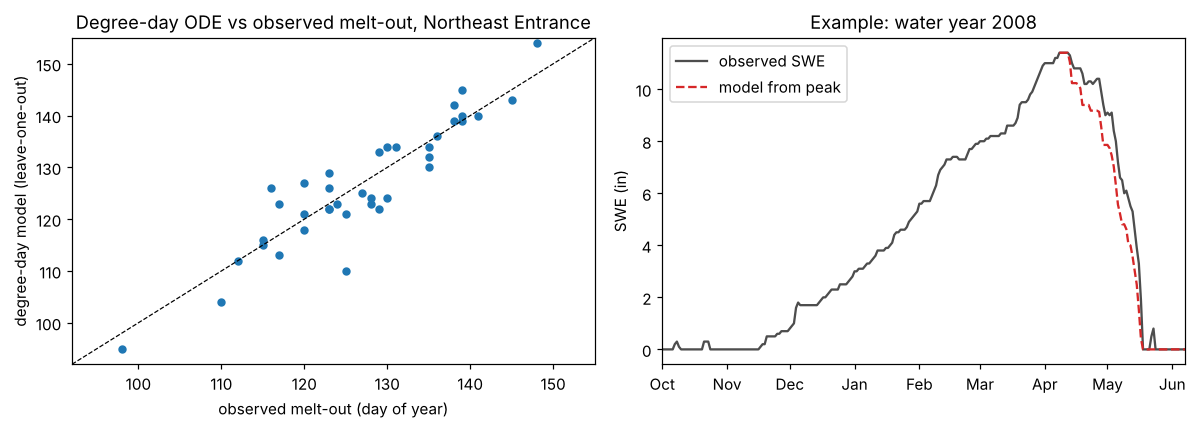

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].scatter(obs_doy, pred_doy, s=20)
lims = [obs_doy.min() - 5, obs_doy.max() + 5]
ax[0].plot(lims, lims, "k--", lw=0.8); ax[0].set_xlim(lims); ax[0].set_ylim(lims)
ax[0].set_xlabel("observed melt-out (day of year)"); ax[0].set_ylabel("degree-day model (leave-one-out)")
ax[0].set_title("Degree-day ODE vs observed melt-out, Northeast Entrance")
wy_ex = int(melt["error_days"].abs().idxmin())
g = ne[ne.wy == wy_ex]
k_ex = melt.drop(index=wy_ex)["k"].median()
path, swe = [], melt.loc[wy_ex, "peak_SWE"]
for day, t in g.loc[melt.loc[wy_ex, "peak_date"]:, "TAVG"].fillna(32).items():
    swe = max(swe - k_ex * max(t - 32, 0), 0); path.append((day, swe))
path = pd.Series(dict(path))
ax[1].plot(g.index, g["SWE"], color="0.3", label="observed SWE")
ax[1].plot(path.index, path.values, "C3--", label="model from peak")
ax[1].set_xlim(g.index.min(), melt.loc[wy_ex, "meltout_date"] + pd.Timedelta(days=20))
ax[1].set_ylabel("SWE (in)"); ax[1].set_title(f"Example: water year {wy_ex}"); ax[1].legend()
import matplotlib.dates as mdates
ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
save(fig, "05_degree_day")

## 5. Can monthly flow be forecast? (SARIMA)

Monthly mean flow, log scale, water years 1911–2026 (1,392 months). Steps: stationarity tests → seasonal differencing → ACF/PACF → compare a few SARIMA orders by AIC/BIC and residual checks → rolling-origin test: for each water year 2017–2026, fit on everything before it and forecast all 12 months; compare with the seasonal naive forecast (each month = same month last year) and the monthly climatology.

In [13]:
def stationarity(x, name):
    x = x.dropna()
    ps = [adfuller(x, maxlag=l, autolag=None)[1] for l in (0, 1, 2)]
    kp = kpss(x, regression="c", nlags="auto")[1]
    return {"series": name, "ADF p (lag 0,1,2)": ", ".join(f"{p:.3f}" for p in ps),
            "KPSS p": round(kp, 3), "ADF says stationary": sum(p < .05 for p in ps) >= 2, "KPSS says stationary": kp >= .05}

pd.DataFrame([stationarity(logm, "log monthly flow"),
              stationarity(logm.diff(12), "seasonal difference Δ12"),
              stationarity(logm.diff(12).diff(), "Δ1Δ12")]).set_index("series")

,"ADF p (lag 0,1,2)",KPSS p,ADF says stationary,KPSS says stationary
series,,,,
log monthly flow,"0.000, 0.000, 0.000",0.1,True,True
seasonal difference Δ12,"0.000, 0.000, 0.000",0.1,True,True
Δ1Δ12,"0.000, 0.000, 0.000",0.1,True,True


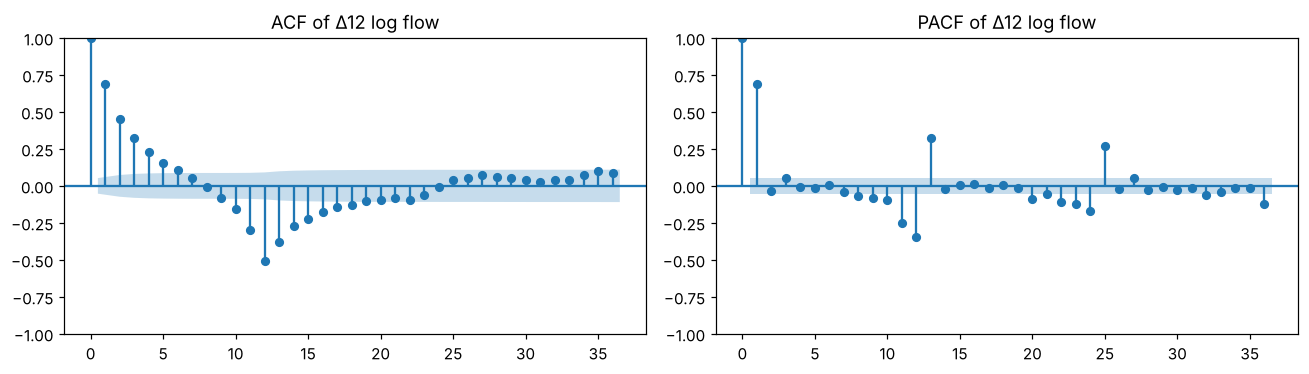

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(logm.diff(12).dropna(), lags=36, ax=ax[0]); ax[0].set_title("ACF of Δ12 log flow")
plot_pacf(logm.diff(12).dropna(), lags=36, ax=ax[1], method="ywm"); ax[1].set_title("PACF of Δ12 log flow")
save(fig, "06_sarima_acf")

In [15]:
cands = {"(1,0,0)(0,1,1)12": ((1, 0, 0), (0, 1, 1, 12)), "(1,0,1)(0,1,1)12": ((1, 0, 1), (0, 1, 1, 12)),
         "(2,0,0)(0,1,1)12": ((2, 0, 0), (0, 1, 1, 12)), "(0,1,1)(0,1,1)12 airline": ((0, 1, 1), (0, 1, 1, 12)),
         "(1,0,0)(1,1,1)12": ((1, 0, 0), (1, 1, 1, 12))}
ident, fits = [], {}
for name, (o, so) in cands.items():
    r = SARIMAX(logm, order=o, seasonal_order=so).fit(disp=False)
    fits[name] = r
    ident.append({"model": name, "AIC": round(r.aic, 1), "BIC": round(r.bic, 1),
                  "Ljung–Box p (lag 24)": round(acorr_ljungbox(r.resid[13:], lags=[24]).lb_pvalue.iloc[0], 3)})
ident = pd.DataFrame(ident).set_index("model").sort_values("BIC")
ident.to_csv(TAB / "P2_sarima_identification.csv")
best = ident.index[0]
print("Chosen by BIC:", best); print(fits[best].summary().tables[1])
ident

Chosen by BIC: (1,0,0)(0,1,1)12
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.7143      0.017     42.545      0.000       0.681       0.747
ma.S.L12      -0.9259      0.008   -123.418      0.000      -0.941      -0.911
sigma2         0.0411      0.001     43.773      0.000       0.039       0.043


,AIC,BIC,Ljung–Box p (lag 24)
model,,,
"(1,0,0)(0,1,1)12",-458.9,-443.2,0.048
"(1,0,1)(0,1,1)12",-460.7,-439.8,0.143
"(2,0,0)(0,1,1)12",-459.8,-438.9,0.113
"(1,0,0)(1,1,1)12",-458.0,-437.1,0.050
"(0,1,1)(0,1,1)12 airline",-273.9,-258.2,0.000


In [16]:
o, so = cands[best]
rows = []
for wy in range(2017, 2027):
    train = logm[: f"{wy - 1}-09-01"]
    test = logm[f"{wy - 1}-10-01": f"{wy}-09-01"]
    fc = SARIMAX(train, order=o, seasonal_order=so).fit(disp=False).forecast(12)
    snaive = train.iloc[-12:].values
    climo = train.groupby(train.index.month).mean().reindex(test.index.month).values
    for name, pred in [("SARIMA", fc.values), ("seasonal naive", snaive), ("climatology", climo)]:
        rows.append({"wy": wy, "model": name, "MAPE": 100 * np.mean(np.abs(np.exp(pred) - np.exp(test.values)) / np.exp(test.values))})
sar_scores = pd.DataFrame(rows).pivot(index="wy", columns="model", values="MAPE").round(1)
sar_scores.loc["mean"] = sar_scores.mean().round(1)
sar_scores.to_csv(TAB / "P2_sarima_rolling.csv")
sar_scores

model,SARIMA,climatology,seasonal naive
wy,,,
2017,34.2,25.8,38.2
2018,20.2,25.9,20.5
2019,9.0,7.0,37.0
2020,7.8,9.8,12.3
2021,27.8,26.6,36.2
2022,28.0,29.9,37.7
2023,13.0,11.9,25.9
2024,19.1,21.1,27.8
2025,31.5,38.8,44.7


## 6. How volatile is the river, and how extreme was the 2022 flood? (Q7, stochastic models)

**Step 1, remove the seasonal cycle.** For each calendar day, subtract the long-run mean of log flow and divide by its long-run standard deviation (both smoothed over ±15 days). What is left, $z_t$, is "how unusual is today's flow for this time of year".

**Step 2, the Ornstein–Uhlenbeck (OU) model.** $dz = -\theta z\,dt + \sigma\,dW$: anomalies drift back to normal at rate $\theta$, with constant noise. In daily steps this is an AR(1) with $\varphi = e^{-\theta}$; the half-life of an anomaly is $\ln 2/\theta$. We also fit AR(p) with p chosen by BIC, since one day of memory may not be enough.

**Step 3, is the noise really constant?** Daily shocks are much bigger in some seasons (snowmelt, river ice) than others, so first divide the AR residuals by their typical size for that calendar day. Then compare three models for what remains, all with Student-t errors so AIC/BIC are comparable:

- **constant variance** (what OU assumes),
- **GARCH(1,1):** big shocks are followed by big shocks (volatility clustering),
- **EGARCH(1,1):** clustering, plus rises and falls in flow can affect volatility differently.

In [17]:
doy = f.index.dayofyear.where(f.index.dayofyear < 366, 365)
circ = lambda s: pd.concat([s.iloc[-15:], s, s.iloc[:15]]).rolling(31, center=True).mean().iloc[15:-15]
mu_s = circ(f["logQ"].groupby(doy).mean())
sd_s = circ(f["logQ"].groupby(doy).std())
z = ((f["logQ"] - mu_s.reindex(doy).values) / sd_s.reindex(doy).values).rename("z")

ar1 = AutoReg(z.values, lags=1, trend="n").fit()
phi = ar1.params[0]; theta = -np.log(phi)
ou = pd.Series({"phi (daily AR1)": round(phi, 4), "theta per day": round(theta, 4),
                "half-life of an anomaly (days)": round(np.log(2) / theta, 1),
                "sigma (OU, per sqrt day)": round(ar1.resid.std() * np.sqrt(2 * theta / (1 - phi ** 2)), 3)})
bics = {L: AutoReg(z.values, lags=L, trend="n", hold_back=10).fit().bic for L in range(1, 11)}
p = min(bics, key=bics.get)                    # AR order by BIC, same estimation sample for every lag
arp = AutoReg(z.values, lags=p, trend="n").fit()
print("OU / AR(1) parameters:"); print(ou.to_string())
print(f"\nAR order chosen by BIC (1–10): {p}.  BIC AR(1) = {bics[1]:.0f}, AR({p}) = {bics[p]:.0f}")

OU / AR(1) parameters:
phi (daily AR1)                    0.9784
theta per day                      0.0218
half-life of an anomaly (days)    31.7000
sigma (OU, per sqrt day)           0.2080

AR order chosen by BIC (1–10): 10.  BIC AR(1) = -13587, AR(10) = -16683


Typical daily shock is 3.6× larger on day 344 of the year than on day 210
ARCH LM test (10 lags): raw residuals p = 0; after seasonal scaling p = 0


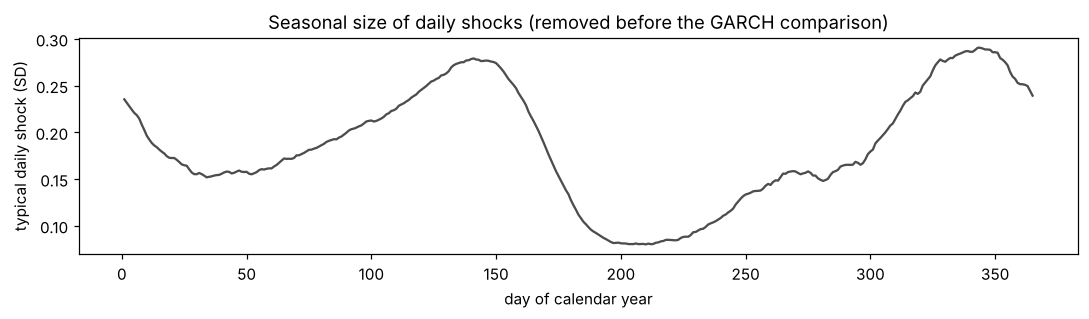

In [18]:
e = pd.Series(arp.resid, index=z.index[p:])
de = e.index.dayofyear.where(e.index.dayofyear < 366, 365)
se = circ(e.groupby(de).std())
es = (e / se.reindex(de).values).rename("scaled shock")
print(f"Typical daily shock is {se.max() / se.min():.1f}× larger on day {se.idxmax()} of the year than on day {se.idxmin()}")
print(f"ARCH LM test (10 lags): raw residuals p = {het_arch(e.values, nlags=10)[1]:.2g}; "
      f"after seasonal scaling p = {het_arch(es.values, nlags=10)[1]:.2g}")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(se.index, se.values, color="0.3"); ax.set_xlabel("day of calendar year"); ax.set_ylabel("typical daily shock (SD)")
ax.set_title("Seasonal size of daily shocks (removed before the GARCH comparison)")
save(fig, "07_seasonal_shock_size")

In [19]:
specs = {"constant variance (OU assumption)": dict(vol="Constant"),
         "GARCH(1,1)": dict(vol="GARCH", p=1, q=1),
         "EGARCH(1,1) with asymmetry": dict(vol="EGARCH", p=1, o=1, q=1)}
vol_fits, rows = {}, []
for name, kw in specs.items():
    r = arch_model(es.values, mean="Zero", dist="t", **kw).fit(disp="off")
    vol_fits[name] = r
    row = {"model": name, "log-lik": round(r.loglikelihood, 1), "AIC": round(r.aic, 1), "BIC": round(r.bic, 1),
           "t dof": round(r.params["nu"], 2), "converged": r.convergence_flag == 0}
    if name.startswith("GARCH"):
        row["persistence (alpha+beta)"] = round(r.params["alpha[1]"] + r.params["beta[1]"], 3)
    if name.startswith("EGARCH"):
        row["persistence (beta)"] = round(r.params["beta[1]"], 3)
        row["asymmetry gamma"] = f"{r.params['gamma[1]']:.3f} (p = {r.pvalues['gamma[1]']:.2g})"
    rows.append(row)
vol = pd.DataFrame(rows).set_index("model")
vol.to_csv(TAB / "P2_volatility_models.csv")
pd.DataFrame({"OU": ou}).to_csv(TAB / "P2_ou_parameters.csv")
vol

,log-lik,AIC,BIC,t dof,converged,persistence (alpha+beta),persistence (beta),asymmetry gamma
model,,,,,,,,
constant variance (OU assumption),-53819.9,107643.9,107661.2,2.49,True,NaN,NaN,NaN
"GARCH(1,1)",-50639.4,101286.7,101321.3,3.40,True,1.0,NaN,NaN
"EGARCH(1,1) with asymmetry",-50242.5,100494.9,100538.2,3.13,True,NaN,0.847,0.071 (p = 5.6e-24)


Reading the table: lower AIC/BIC is better. A large drop from constant variance to GARCH means volatility clustering is real even after the seasonal pattern is removed, so the OU model's constant-noise assumption fails. In EGARCH, a positive asymmetry γ means unexpected *rises* in flow raise volatility more than unexpected falls; persistence near 1 means turbulent spells last a long time. Low t degrees of freedom mean very heavy tails (occasional huge shocks).

Best volatility model by BIC: EGARCH(1,1) with asymmetry
2022 flood: flow on 13 June was 3.7 SD above normal for the date (highest anomaly in the record: 2016-10-31, 4.5 SD).
Largest single-day shock in June 2022: +3.3 on 2022-06-13; a shock this size happens on about 1 day in 94 under the fitted model.
Rank of that shock among all 42,359 days: 429


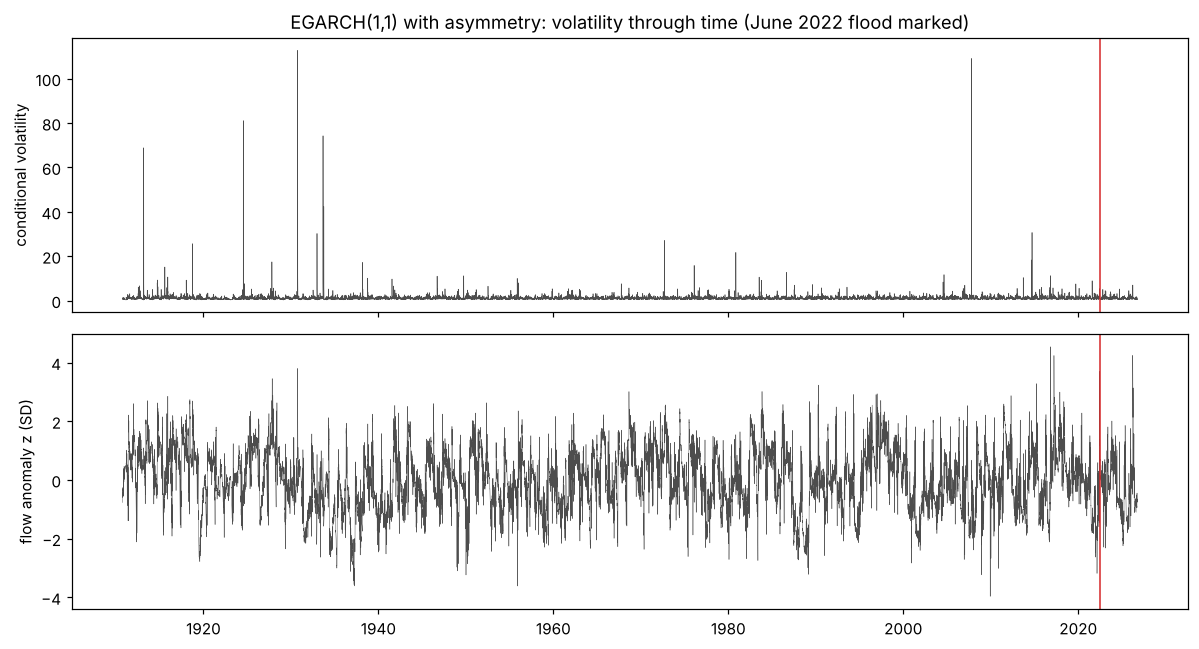

In [20]:
best_vol = vol["BIC"].idxmin()
rv = vol_fits[best_vol]
cv = pd.Series(rv.conditional_volatility, index=es.index)
sr = pd.Series(rv.std_resid, index=es.index)
win = slice("2022-06-01", "2022-06-30")
top = sr[win].abs().idxmax()
nu = rv.params["nu"]
tail = 2 * stats.t.sf(abs(sr[top]) * np.sqrt(nu / (nu - 2)), nu)
print(f"Best volatility model by BIC: {best_vol}")
print(f"2022 flood: flow on 13 June was {z.loc['2022-06-13']:.1f} SD above normal for the date (highest anomaly in the record: {z.idxmax().date()}, {z.max():.1f} SD).")
print(f"Largest single-day shock in June 2022: {sr[top]:+.1f} on {top.date()}; a shock this size happens on about 1 day in {1 / tail:,.0f} under the fitted model.")
print(f"Rank of that shock among all {len(sr):,} days: {(sr.abs() >= abs(sr[top])).sum()}")

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(cv.index, cv, lw=0.4, color="0.3"); ax[0].set_ylabel("conditional volatility")
ax[0].set_title(f"{best_vol}: volatility through time (June 2022 flood marked)")
ax[1].plot(z.index, z, lw=0.3, color="0.3"); ax[1].set_ylabel("flow anomaly z (SD)")
for a_ in ax: a_.axvline(pd.Timestamp("2022-06-13"), color="C3", lw=1)
save(fig, "08_volatility")

### How rare was the 2022 peak? (extreme-value fits)

Fit distributions to each water year's peak daily flow, **leaving 2022 out**, then ask how often a peak of 2022's size would be expected:

- **GEV** (generalised extreme value) estimates the tail shape from the data. In scipy's convention a positive shape c means the fitted tail has an upper limit.
- **Gumbel** is the GEV with shape fixed at 0 (an unbounded, thin tail), a common default for floods.

The two answers differ hugely, which is the honest result: a peak almost 50% above the previous 116-year record is far outside the data, so its return period depends almost entirely on an assumption about the tail. Report the range, not a single number.

In [21]:
peaks = ann["peak_Q"] / 1000                     # thousands of cfs (helps the optimiser)
pk22, base = peaks.loc[2022], peaks.drop(index=2022)
c, loc, scale = stats.genextreme.fit(base.values)
upper = loc + scale / c if c > 0 else np.inf
rp_gev = 1 / max(stats.genextreme.sf(pk22, c, loc, scale), 1e-300)
gl, gs = stats.gumbel_r.fit(base.values)
rp_gum = 1 / stats.gumbel_r.sf(pk22, gl, gs)
rng = np.random.default_rng(42)
boot = [1 / stats.gumbel_r.sf(pk22, *stats.gumbel_r.fit(rng.choice(base.values, len(base)))) for _ in range(500)]
lo_, hi_ = np.percentile(boot, [5, 95])
print(f"2022 peak: {pk22 * 1000:,.0f} cfs; previous record {base.max() * 1000:,.0f} cfs ({int(base.idxmax())}), so {100 * (pk22 / base.max() - 1):.0f}% higher")
print(f"GEV: shape c = {c:.3f}; fitted upper limit {upper * 1000:,.0f} cfs; return period of 2022 ≈ {rp_gev:.2g} years (driven by the bounded tail)")
print(f"Gumbel: return period ≈ {rp_gum:,.0f} years (90% bootstrap {lo_:,.0f}–{hi_:,.0f})")
pd.DataFrame({"2022 peak cfs": [pk22 * 1000], "previous record cfs": [base.max() * 1000], "GEV shape c": [round(c, 3)],
              "GEV upper limit cfs": [round(upper * 1000)], "GEV return period yr": [rp_gev],
              "Gumbel return period yr": [round(rp_gum)], "Gumbel 5%": [round(lo_)], "Gumbel 95%": [round(hi_)]}).to_csv(
    TAB / "P2_flood_return_period.csv", index=False)

2022 peak: 47,200 cfs; previous record 32,000 cfs (1918), so 48% higher
GEV: shape c = 0.118; fitted upper limit 51,968 cfs; return period of 2022 ≈ 3.4e+07 years (driven by the bounded tail)
Gumbel: return period ≈ 2,078 years (90% bootstrap 1,020–5,458)


## 7. Summary

The cell below prints the key numbers. Write the plain-English conclusions under it after reading them; the main ones:

1. **Timing (Q5):** has the centre of timing moved earlier since 1950, and by how much compared with the Climate Assessment's ~8 days?
2. **Snow → river (Q4/Q5):** how much of the river's timing and volume does the snowpack explain?
3. **Melt model (Q4):** does the one-parameter degree-day ODE beat the "average day" benchmark?
4. **Volatility (Q7):** is volatility clustering real (GARCH vs OU), and is there asymmetry?
5. **2022 flood:** how unusual for the date, how extreme as a daily shock, and how its return period depends on the tail assumption.

Caveats: provisional data for the last months; SNOTEL temperature-sensor change; GEV extrapolation; this river integrates a huge area, so none of this tests a wolf effect on rivers, which is about small-stream channels (Beschta & Ripple 2020). It tests the water side of the debate.

In [22]:
print(timing_trends[["Sen slope per decade", "MK p", "MK p (autocorr-corrected)"]].to_string())
print()
print(snow_river.to_string(index=False))
print()
print(vol.to_string())

                                      Sen slope per decade    MK p  MK p (autocorr-corrected)
series                                                                                       
centre of timing (days), from 1911                  -0.812  0.0020                     0.0020
peak date (days), from 1911                         -0.788  0.0189                     0.0267
log mean flow, from 1911                             0.001  0.8805                     0.8805
log summer 7-day low flow, from 1911                -0.013  0.1017                     0.1636
share of flow in Apr–May, from 1911                  0.008  0.0001                     0.0004
centre of timing (days), from 1950                  -1.771  0.0001                     0.0001
peak date (days), from 1950                         -1.935  0.0015                     0.0015
log mean flow, from 1950                            -0.013  0.3013                     0.3013
log summer 7-day low flow, from 1950                -0.032  